In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

heart = fetch_ucirepo(id=45)   # UCI Heart Disease dataset

X = heart.data.features
y = heart.data.targets

df = pd.concat([X, y], axis=1)
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [3]:
df.info()
print(df.isnull().sum())
print(df['num'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64
num
0    1

In [4]:
# Fill missing values with the most common value
df['ca'] = df['ca'].fillna(df['ca'].mode()[0])
df['thal'] = df['thal'].fillna(df['thal'].mode()[0])

# Convert target: 0 = no disease, 1 = disease
df['target'] = (df['num'] > 0).astype(int)
df = df.drop('num', axis=1)

print(df.isnull().sum().sum())      # should print 0
print(df['target'].value_counts())

0
target
0    164
1    139
Name: count, dtype: int64


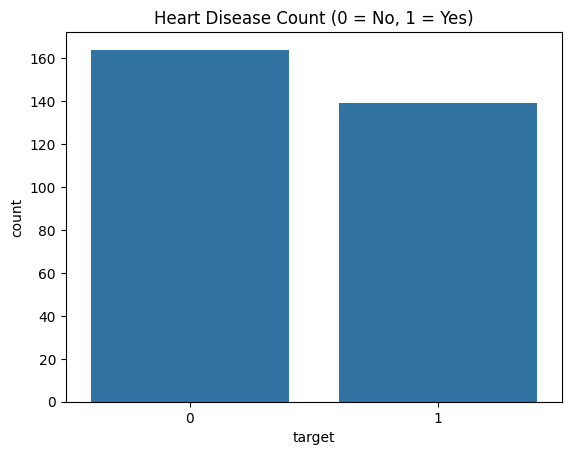

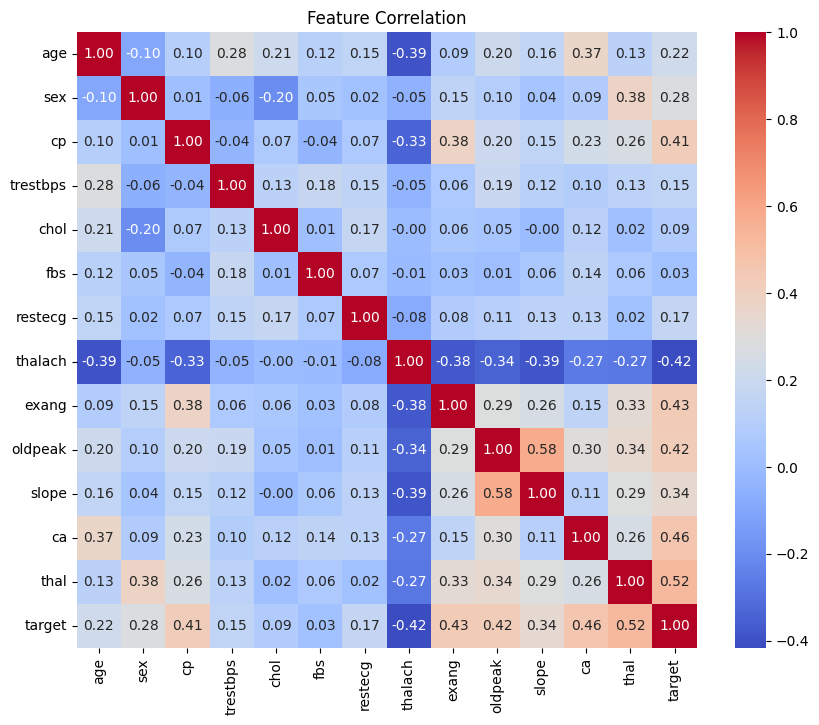

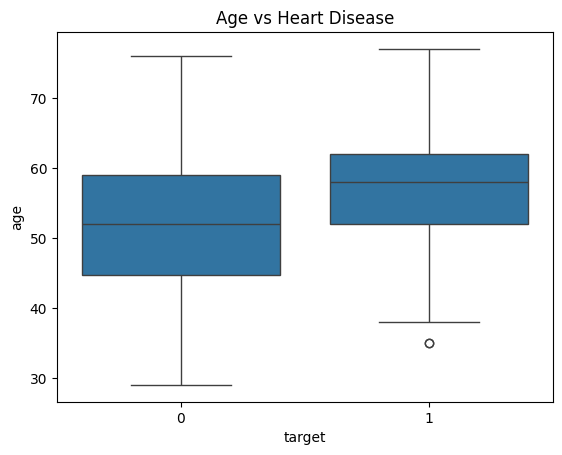

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Disease vs no disease
sns.countplot(x='target', data=df)
plt.title('Heart Disease Count (0 = No, 1 = Yes)')
plt.show()

# 2. Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation')
plt.show()

# 3. Age vs disease
sns.boxplot(x='target', y='age', data=df)
plt.title('Age vs Heart Disease')
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(242, 13) (61, 13)


In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'SVM': make_pipeline(StandardScaler(), SVC(probability=True, random_state=42)),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.869,0.812,0.929,0.867,0.951
1,SVM,0.852,0.806,0.893,0.847,0.944
2,Random Forest,0.902,0.844,0.964,0.900,0.955
3,XGBoost,0.852,0.788,0.929,0.852,0.919


In [8]:
from sklearn.model_selection import cross_val_score

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    print(f"{name}: {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: 0.828 (+/- 0.036)
SVM: 0.828 (+/- 0.046)
Random Forest: 0.815 (+/- 0.053)
XGBoost: 0.808 (+/- 0.035)


              precision    recall  f1-score   support

  No Disease       0.93      0.82      0.87        33
     Disease       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



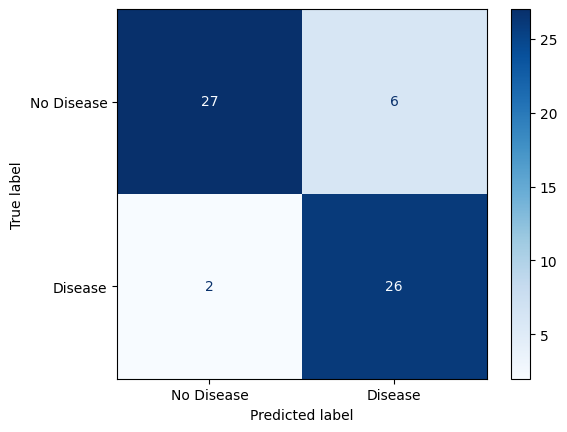

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

best_model = models['Logistic Regression']
pred = best_model.predict(X_test)

print(classification_report(y_test, pred, target_names=['No Disease', 'Disease']))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=['No Disease', 'Disease']).plot(cmap='Blues')
plt.show()

In [ ]:
import joblib
from google.colab import files

final_model = models['Logistic Regression']

joblib.dump(final_model, 'heart_model.pkl')
joblib.dump(list(X.columns), 'features.pkl')

files.download('heart_model.pkl')
files.download('features.pkl')